# Drone training analysis

1. **Training history** — mean episode reward vs. timesteps (from the TensorBoard logs).
2. **Test rollout** — one deterministic episode: x/y/z position, velocities, and a top-down XY trajectory.

In [29]:
import glob
import os

import numpy as np
import matplotlib.pyplot as plt

from environment import DroneEnv
from stable_baselines3 import PPO

# Colorblind-safe palette (Okabe-Ito) for the x / y / z series.
CXYZ = {"x": "#0072B2", "y": "#E69F00", "z": "#009E73"}

plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.grid": True,
    "grid.color": "0.9",       # recessive grid
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 2.0,
})

MODELS_DIR = "models"
LOGS_DIR = "logs"

## 1. Training history

Reads `rollout/ep_rew_mean` straight from the latest TensorBoard event file.

Reading run: logs/PPO_20261006_001125_1
90 points, timesteps 64000..5760000


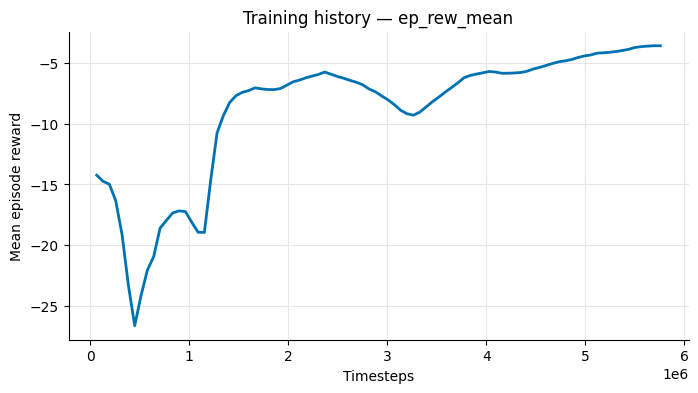

In [30]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator


def load_scalar(logs_dir, tag="rollout/ep_rew_mean"):
    """Return (steps, values) for `tag` across the ENTIRE latest run.

    SB3 writes a new event file per `learn()` call, all into the same run
    directory. Pointing EventAccumulator at that directory aggregates every
    chunk, so this plots the full history rather than just the last block.
    """
    event_files = glob.glob(os.path.join(logs_dir, "**", "events.out.tfevents.*"), recursive=True)
    if not event_files:
        raise FileNotFoundError(f"No TensorBoard event files under {logs_dir!r}")
    # The run directory holding the most recently written event file.
    run_dir = os.path.dirname(max(event_files, key=os.path.getmtime))
    print(f"Reading run: {run_dir}")

    # size_guidance=0 -> keep ALL scalar points (default downsamples to 1000).
    ea = EventAccumulator(run_dir, size_guidance={"scalars": 0})
    ea.Reload()
    if tag not in ea.Tags().get("scalars", []):
        raise KeyError(f"Tag {tag!r} not found. Available: {ea.Tags().get('scalars', [])}")
    events = ea.Scalars(tag)
    steps = np.array([e.step for e in events])
    values = np.array([e.value for e in events])
    order = np.argsort(steps)  # merge across files may be out of order
    return steps[order], values[order]


steps, rew = load_scalar(LOGS_DIR)
print(f"{len(steps)} points, timesteps {steps.min()}..{steps.max()}")

fig, ax = plt.subplots()
ax.plot(steps, rew, color="#0072B2")
ax.set_xlabel("Timesteps")
ax.set_ylabel("Mean episode reward")
ax.set_title("Training history — ep_rew_mean")
plt.show()

## 2. Test rollout

Loads the most recent saved model and runs one deterministic episode in a single-env `DroneEnv`.

In [31]:
def latest_model(models_dir):
    zips = glob.glob(os.path.join(models_dir, "**", "*.zip"), recursive=True)
    if not zips:
        raise FileNotFoundError(f"No .zip models under {models_dir!r}")
    return max(zips, key=os.path.getmtime)


model_path = latest_model(MODELS_DIR)
print(f"Loading: {model_path}")
model = PPO.load(model_path)

# Single-env instance so we can read the full state directly.
env = DroneEnv(num_envs=1)
target = env.target.copy()

obs = env.reset()
positions, velocities, actions = [], [], []
for _ in range(env.max_episode_steps):
    positions.append(env.states[0, 0:3].copy())    # x, y, z
    velocities.append(env.states[0, 7:10].copy())  # vx, vy, vz
    action, _ = model.predict(obs, deterministic=True)
    actions.append(action[0].copy())               # [thrust, p, q, r] command
    obs, reward, dones, infos = env.step(action)
    if dones[0]:
        break

positions = np.array(positions)
velocities = np.array(velocities)
actions = np.array(actions)
t = np.arange(len(positions)) * env.dt
print(f"Rollout length: {len(positions)} steps ({t[-1]:.2f}s)")

Loading: models/PPO_20261006_001125/5760000.zip
Rollout length: 1000 steps (9.99s)


### Position vs. time

NED frame (z positive down). Dashed lines mark the target for each axis.

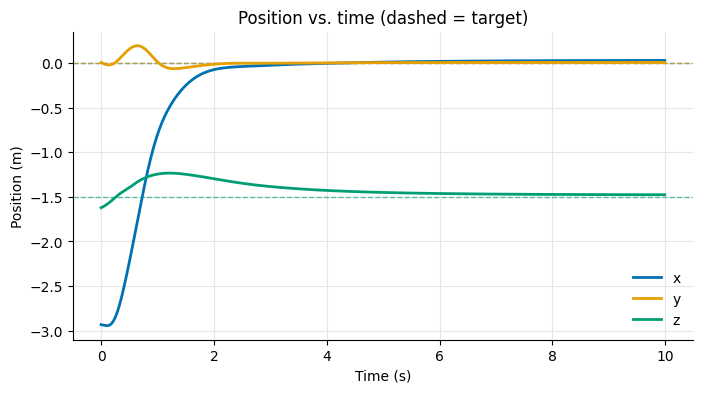

In [32]:
fig, ax = plt.subplots()
for i, axis in enumerate(["x", "y", "z"]):
    ax.plot(t, positions[:, i], color=CXYZ[axis], label=axis)
    ax.axhline(target[i], color=CXYZ[axis], linestyle="--", linewidth=1, alpha=0.6)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Position (m)")
ax.set_title("Position vs. time (dashed = target)")
ax.legend(frameon=False)
plt.show()

### Velocity vs. time

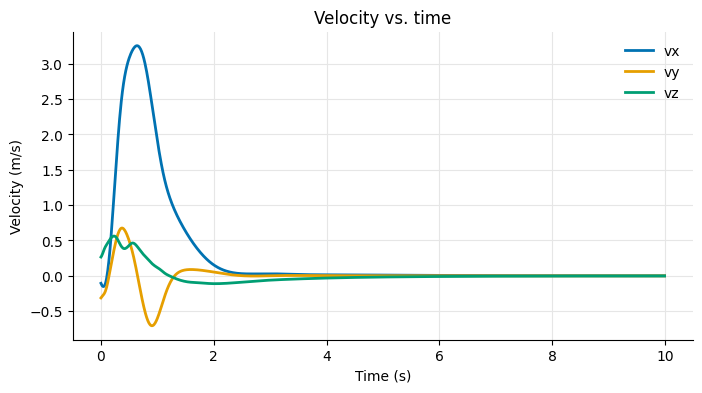

In [33]:
fig, ax = plt.subplots()
for i, axis in enumerate(["x", "y", "z"]):
    ax.plot(t, velocities[:, i], color=CXYZ[axis], label=f"v{axis}")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Velocity (m/s)")
ax.set_title("Velocity vs. time")
ax.legend(frameon=False)
plt.show()

### Top-down XY trajectory

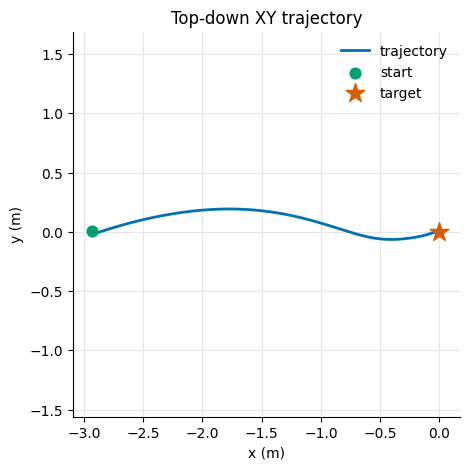

In [34]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(positions[:, 0], positions[:, 1], color="#0072B2", label="trajectory")
ax.scatter(positions[0, 0], positions[0, 1], color="#009E73", s=60, zorder=3, label="start")
ax.scatter(target[0], target[1], color="#D55E00", marker="*", s=200, zorder=3, label="target")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Top-down XY trajectory")
ax.set_aspect("equal", adjustable="datalim")
ax.legend(frameon=False)
plt.show()

### Actions vs. time

Policy output (pre-clip) per channel: collective thrust and the body-rate
commands [p, q, r]. Dashed lines at ±1 mark the action-space bounds — anything
beyond them is clipped before reaching the dynamics.

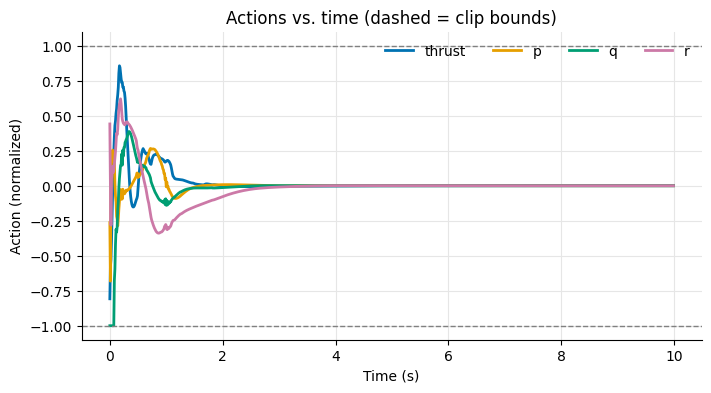

In [35]:
# Action channels and colorblind-safe (Okabe-Ito) colors.
ACT_LABELS = ["thrust", "p", "q", "r"]
ACT_COLORS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]

fig, ax = plt.subplots()
for i, (label, color) in enumerate(zip(ACT_LABELS, ACT_COLORS)):
    ax.plot(t, actions[:, i], color=color, label=label)
ax.axhline(1.0, color="0.5", linestyle="--", linewidth=1)
ax.axhline(-1.0, color="0.5", linestyle="--", linewidth=1)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Action (normalized)")
ax.set_title("Actions vs. time (dashed = clip bounds)")
ax.legend(frameon=False, ncol=4, loc="upper right")
plt.show()